# Estadística descriptiva

### Entorno y persistencia de resultados

En la celda siguiente fijé tres cosas que condicionan la reproducibilidad del experimento.

**Semilla fija.** Usé `RANDOM_STATE = 42` en la partición train/test y en el ajuste de todos los
modelos. Sin ella, cada ejecución produciría particiones distintas y las métricas no serían
comparables entre corridas ni verificables por un tercero.

**Persistencia en Google Drive.** Escribí los resultados en `MyDrive/bank_marketing` y no en el
disco temporal de Colab, que se borra al cerrar la sesión. El notebook 03 deja las particiones
preparadas y los notebooks 04 y 05 las consumen tal cual, de modo que todos operan sobre exactamente
los mismos datos. Si el montaje no se completa, la celda interrumpe la ejecución en lugar de escribir
en una ubicación volátil. Fuera de Colab no hace falta Drive, y los resultados se escriben en la
carpeta del repositorio (los gráficos en `splits/`).

**Registro de las figuras.** La función `guardar` escribe cada gráfico en `splits/` como PNG a 200
dpi. La invoco antes de `plt.show()`, porque mostrar la figura vacía el buffer de matplotlib y el
archivo saldría en blanco.

In [1]:
import os, io, time, json, zipfile, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

EN_DRIVE = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError(
            "Drive no quedó montado. Vuelve a ejecutar esta celda y autoriza el acceso "
            "en la ventana emergente."
        )
    RUTA = "/content/drive/MyDrive/bank_marketing"
    EN_DRIVE = True
except ImportError:
    RUTA = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")

CARPETA_SPLITS = os.path.join(RUTA, "splits")
os.makedirs(CARPETA_SPLITS, exist_ok=True)

def guardar(nombre):
    destino = os.path.join(CARPETA_SPLITS, nombre + ".png")
    plt.savefig(destino, dpi=200, bbox_inches="tight", facecolor="white")
    print("Gráfico guardado:", destino)

print("Guardando en Google Drive" if EN_DRIVE else "Google Drive no disponible: guardando localmente")
print("Ruta de trabajo:", RUTA)

Google Drive no disponible: guardando localmente
Ruta de trabajo: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing


## Datos y variable objetivo

Cargué el conjunto con la misma función del notebook 01 y construí `contrato`, la versión numérica de la
variable objetivo (1 si contrató, 0 si no). Separé la columna `duration` en un objeto aparte, porque la
analizo solo para documentar por qué se descarta y no vuelve a usarse.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
ARCHIVO_LOCAL = os.path.join(RUTA, "bank-full.csv")

def cargar_datos():
    if os.path.exists(ARCHIVO_LOCAL):
        return pd.read_csv(ARCHIVO_LOCAL, sep=";")
    with urllib.request.urlopen(URL, timeout=120) as respuesta:
        externo = zipfile.ZipFile(io.BytesIO(respuesta.read()))
    interno = zipfile.ZipFile(io.BytesIO(externo.read("bank.zip")))
    datos = pd.read_csv(interno.open("bank-full.csv"), sep=";")
    datos.to_csv(ARCHIVO_LOCAL, sep=";", index=False)
    return datos

df = cargar_datos()
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])

Filas: 45211 | Columnas: 17


     casos  porcentaje
y                     
no   39922        88.3
yes   5289        11.7


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\02_distribucion_objetivo.png


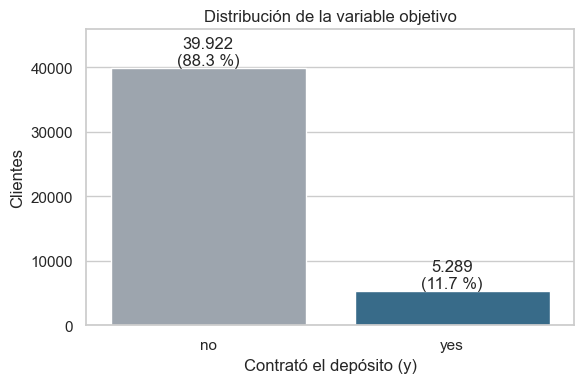

In [3]:
df["contrato"] = (df["y"] == "yes").astype(int)
duracion = df["duration"]
df = df.drop(columns=["duration"])

columnas_numericas = ["age", "balance", "day", "campaign", "pdays", "previous"]
conteo = df["y"].value_counts()
porcentaje = (100 * conteo / len(df)).round(2)
print(pd.DataFrame({"casos": conteo, "porcentaje": porcentaje}))

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=conteo.index, y=conteo.values, hue=conteo.index, palette=["#9aa5b1", "#2a6f97"], legend=False)
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}\n({porcentaje.iloc[i]} %)".replace(",", "."), ha="center", va="bottom")
ax.set_xlabel("Contrató el depósito (y)")
ax.set_ylabel("Clientes")
ax.set_ylim(0, conteo.max() * 1.15)
plt.title("Distribución de la variable objetivo")
plt.tight_layout()
guardar("02_distribucion_objetivo")
plt.show()

**Lectura.** La clase positiva es minoritaria (11,7 %). La figura confirma que cualquier análisis que
mida el éxito del modelo debe mirar la clase `yes` por separado y no el promedio global.

## Estadística descriptiva de las variables numéricas

Calculé media, mediana, desviación, cuartiles, mínimo, máximo y asimetría. Una asimetría positiva fuerte
indica que la media queda lejos de la mediana por culpa de unos pocos valores muy altos.

In [4]:
descriptiva = df[columnas_numericas].describe().T
descriptiva["asimetria"] = df[columnas_numericas].skew()
descriptiva.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0,0.68
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0,8.36
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0,0.09
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0,4.90
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0,2.62
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0,41.85


**Lectura.** Las variables de conteo y de dinero tienen colas muy largas. `balance` tiene una media de
1.362 euros contra una mediana de 448, y llega a 102.127 con una asimetría de 8,36. `campaign` (media
2,76, máximo 63) y sobre todo `previous` (mediana 0, máximo 275, asimetría 41,85) están dominadas por
unos pocos clientes muy contactados. `pdays` vale -1 para la mayoría, así que su media de 40 días no
describe a nadie en particular. `age` y `day` son bastante simétricas.

## Distribución de las variables numéricas

Grafiqué la forma de cada variable por clase, con las densidades normalizadas dentro de cada clase para
que el tamaño distinto de los grupos no distorsione la comparación. Recorté el eje entre los percentiles 1
y 99 de cada variable para ver la parte principal de la distribución (los valores extremos los revisé en
la sección de atípicos). En `pdays` usé solo los clientes contactados antes.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\02_histogramas_numericas.png


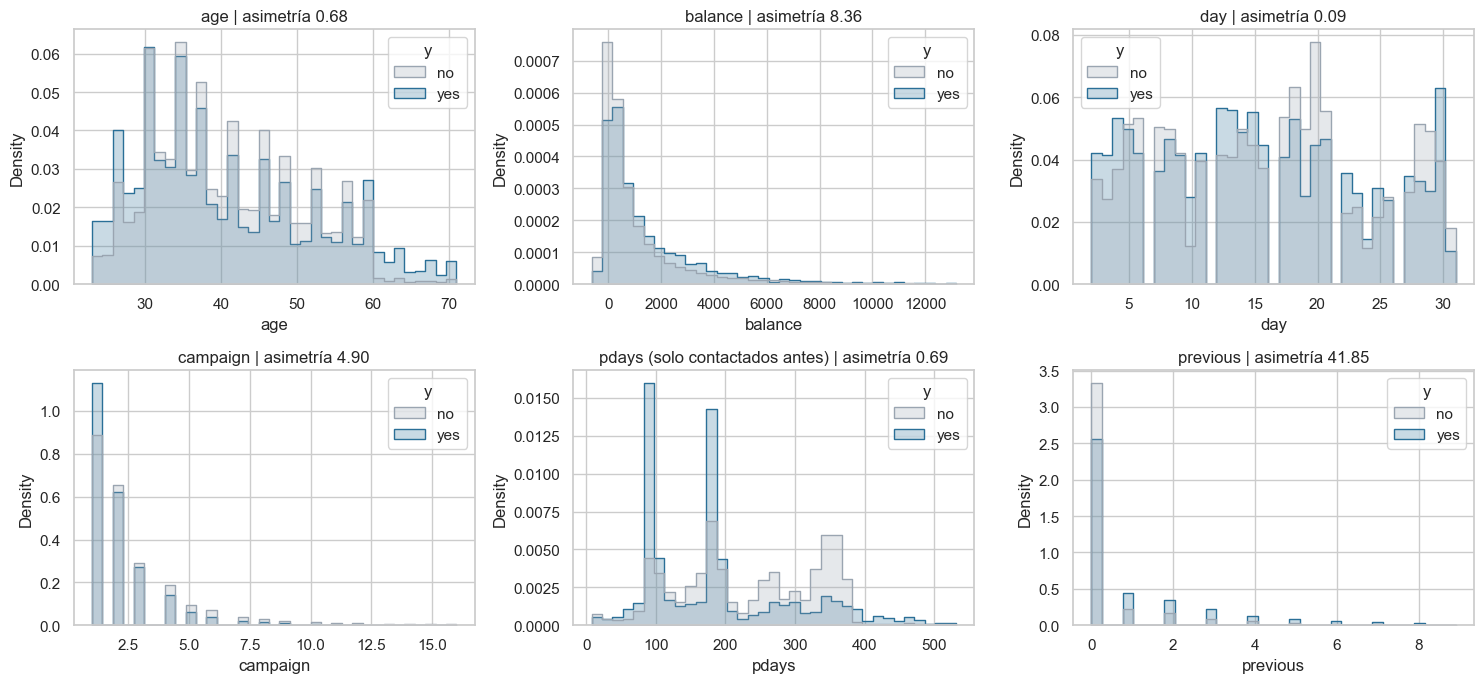

In [5]:
fig, ejes = plt.subplots(2, 3, figsize=(15, 7))
for eje, col in zip(ejes.ravel(), columnas_numericas):
    datos = df if col != "pdays" else df[df["pdays"] > -1]
    bajo, alto = datos[col].quantile([0.01, 0.99])
    sns.histplot(data=datos, x=col, hue="y", stat="density", common_norm=False, bins=35, binrange=(bajo, alto),
                 palette=["#9aa5b1", "#2a6f97"], element="step", ax=eje)
    eje.set_title(f"{col}" + (" (solo contactados antes)" if col == "pdays" else "") + f" | asimetría {datos[col].skew():.2f}")
    eje.set_xlabel(col)
plt.tight_layout()
guardar("02_histogramas_numericas")
plt.show()

**Lectura.** Los histogramas confirman lo que sugerían las medidas. `balance`, `campaign` y `previous` tienen
una concentración enorme cerca de cero y una cola derecha larga, de modo que la mayoría de los clientes
tiene saldos bajos, uno o dos contactos y ningún contacto previo. `age` se concentra entre 30 y 40 años, y
los contratadores pesan más por debajo de 30 y por encima de 60 años. `day` no tiene forma clara, solo
picos en los días de pago. En `pdays` aparecen picos marcados alrededor de 90, 180 y 350 días, que
corresponden a campañas trimestrales y semestrales, y los contratadores se concentran en los dos
primeros. Estas formas explican por qué el escalado importa para el SVM y por qué los árboles, que solo
comparan con umbrales, no lo necesitan.

## Medidas por clase

Comparé la mediana de cada variable entre quienes contratan y quienes no, para ver cuáles podrían separar
a las clases. Usé la mediana porque varias variables tienen colas largas que distorsionan la media.

In [6]:
por_clase = df.groupby("y")[columnas_numericas].agg(["mean", "median", "std"]).T.round(2)
por_clase

y                     no      yes
age      mean      40.84    41.67
         median    39.00    38.00
         std       10.17    13.50
balance  mean    1303.71  1804.27
         median   417.00   733.00
         std     2974.20  3501.10
day      mean      15.89    15.16
         median    16.00    15.00
         std        8.29     8.50
campaign mean       2.85     2.14
         median     2.00     2.00
         std        3.21     1.92
pdays    mean      36.42    68.70
         median    -1.00    -1.00
         std       96.76   118.82
previous mean       0.50     1.17
         median     0.00     0.00
         std        2.26     2.55

**Lectura.** Quienes contratan tienen una mediana de saldo más alta (733 contra 417 euros), fueron
contactados menos veces en esta campaña (media de 2,14 contra 2,85) y tienen más contactos previos
(media de 1,17 contra 0,50). La edad casi no separa las clases (mediana de 38 contra 39 años), aunque
entre los contratadores hay más dispersión (desviación de 13,5 contra 10,2), señal de que se concentran
también en edades extremas.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\02_boxplots_por_clase.png


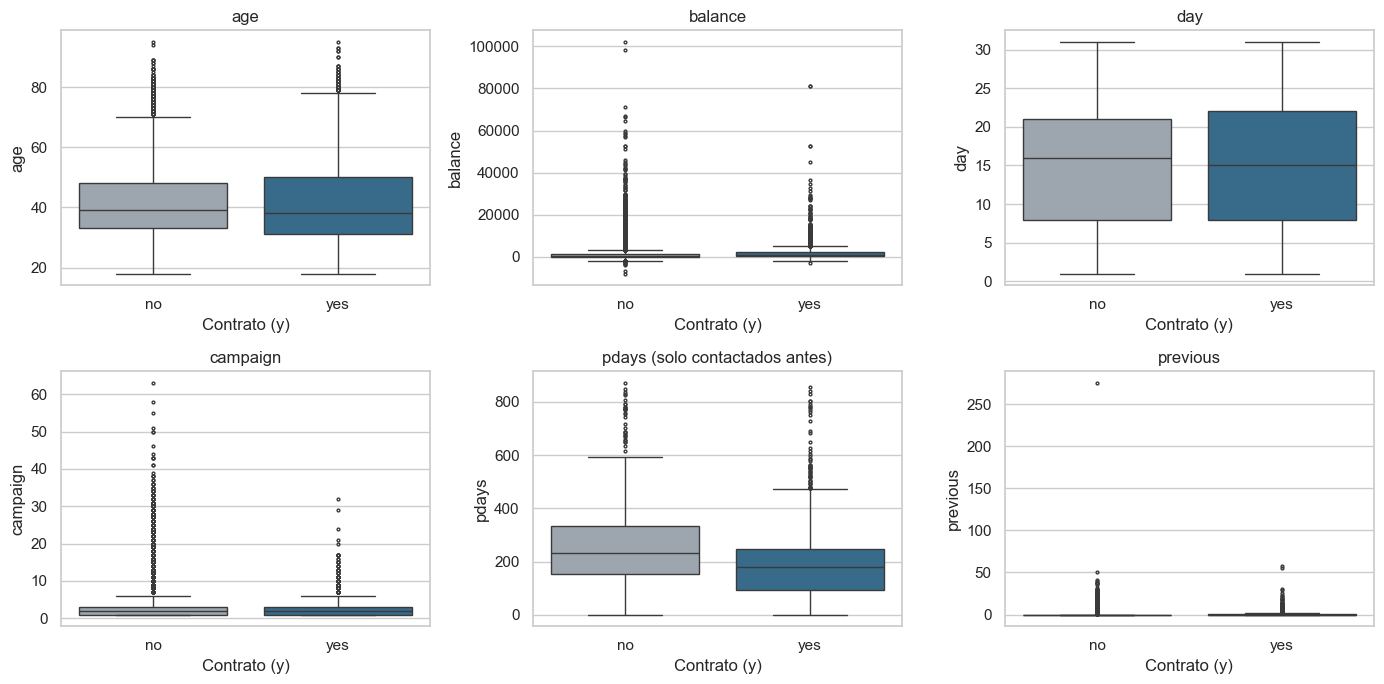

In [7]:
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for eje, col in zip(ejes.ravel(), columnas_numericas):
    datos = df if col != "pdays" else df[df["pdays"] > -1]
    sns.boxplot(data=datos, x="y", y=col, hue="y", palette=["#9aa5b1", "#2a6f97"], legend=False, ax=eje, fliersize=2)
    eje.set_xlabel("Contrato (y)")
    eje.set_title(col + (" (solo contactados antes)" if col == "pdays" else ""))
plt.tight_layout()
guardar("02_boxplots_por_clase")
plt.show()

**Lectura.** Las cajas de `balance`, `campaign`, `previous` y `pdays` están comprimidas contra el cero
por la cantidad de puntos extremos, y las cajas de las dos clases se traslapan mucho. Ninguna de estas
variables separa por sí sola a los contratadores. Para `pdays` solo se grafican los clientes
contactados antes, porque el -1 aplastaría la escala.

## Valores atípicos

Conté los atípicos con la regla del rango intercuartílico (valores a más de 1,5 veces el IQR de los
cuartiles). Lo traté como un diagnóstico y no como una instrucción de eliminar. En el notebook 03 decidí
qué hacer con cada caso.

In [8]:
filas = []
for col in columnas_numericas:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fuera = ((df[col] < inferior) | (df[col] > superior)).sum()
    filas.append({"variable": col, "limite_inferior": inferior, "limite_superior": superior,
                  "atipicos": int(fuera), "porcentaje": round(100 * fuera / len(df), 2),
                  "maximo": df[col].max()})
pd.DataFrame(filas).set_index("variable")

,limite_inferior,limite_superior,atipicos,porcentaje,maximo
variable,,,,,
age,10.5,70.5,487,1.08,95
balance,-1962.0,3462.0,4729,10.46,102127
day,-11.5,40.5,0,0.00,31
campaign,-2.0,6.0,3064,6.78,63
pdays,-1.0,-1.0,8257,18.26,871
previous,0.0,0.0,8257,18.26,275


**Lectura.** Con la regla del IQR, 10,46 % de los saldos y 6,78 % de las cantidades de contactos en
la campaña son atípicos. En `pdays` y `previous` el 18,26 % aparece como atípico porque el rango
intercuartílico es cero (más del 75 % de los clientes tiene el mismo valor), de modo que cualquier
cliente contactado antes queda marcado. Eso es un efecto de la regla y no un error de captura. Ningún
valor se eliminó, porque los extremos son plausibles (saldos altos, clientes insistentemente llamados).

## Correlaciones

Calculé la correlación de Pearson entre las variables numéricas y la de cada una con `contrato` (que, al
ser binaria, equivale a la correlación punto-biserial). Una correlación cercana a cero no implica que la
variable sea inútil, solo descarta una relación lineal.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\02_matriz_correlacion.png


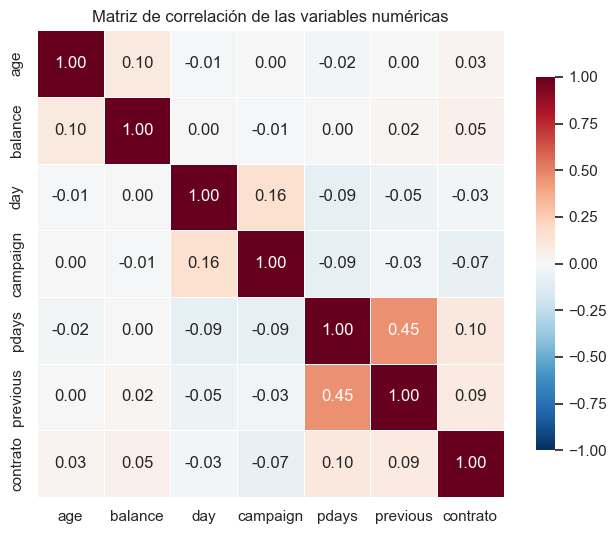

pdays       0.104
previous    0.093
campaign   -0.073
balance     0.053
day        -0.028
age         0.025
Name: contrato, dtype: float64


In [9]:
correlaciones = df[columnas_numericas + ["contrato"]].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlación de las variables numéricas")
plt.tight_layout()
guardar("02_matriz_correlacion")
plt.show()

print(correlaciones["contrato"].drop("contrato").sort_values(key=abs, ascending=False).round(3))

**Lectura.** Las correlaciones con la contratación son todas débiles. La más alta es la de `pdays`
(0,104), seguida por `previous` (0,093), `campaign` en sentido negativo (-0,073) y `balance` (0,053).
Entre las predictoras no aparece ningún par fuertemente correlacionado, así que no hay redundancia que
obligue a retirar variables. Una correlación lineal baja no significa que la variable sea inútil (la
relación con `pdays` o con el mes no es lineal), pero sí anticipa que el problema es difícil y que
ningún modelo va a obtener métricas altas con estos datos.

## Tasa de contratación por categoría

Para las variables categóricas calculé qué porcentaje de cada categoría contrató. Tomé la tasa general
como línea de referencia, de modo que una categoría por encima de ella es más prometedora que el
promedio.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\02_tasa_contratacion_por_categoria.png


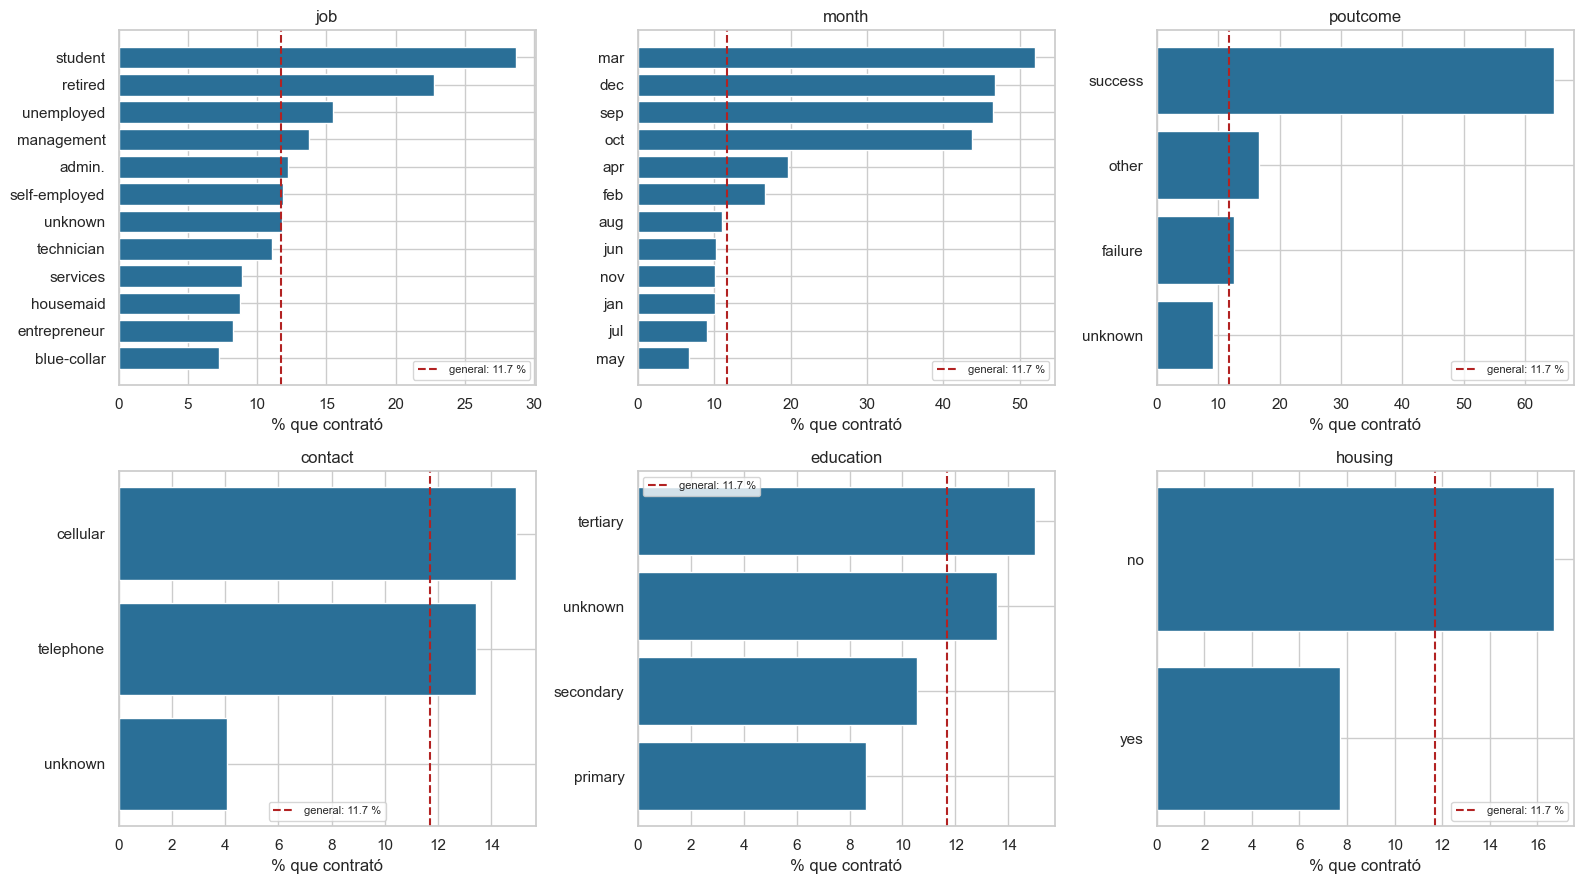

          tasa_%  clientes
poutcome                  
failure    12.61      4901
other      16.68      1840
success    64.73      1511
unknown     9.16     36959


In [10]:
tasa_general = 100 * df["contrato"].mean()
variables = ["job", "month", "poutcome", "contact", "education", "housing"]

fig, ejes = plt.subplots(2, 3, figsize=(16, 9))
for eje, col in zip(ejes.ravel(), variables):
    tasa = (100 * df.groupby(col)["contrato"].mean()).sort_values()
    eje.barh(tasa.index, tasa.values, color="#2a6f97")
    eje.axvline(tasa_general, color="firebrick", linestyle="--", label=f"general: {tasa_general:.1f} %")
    eje.set_title(col)
    eje.set_xlabel("% que contrató")
    eje.legend(fontsize=8)
plt.tight_layout()
guardar("02_tasa_contratacion_por_categoria")
plt.show()

tasa_poutcome = (100 * df.groupby("poutcome")["contrato"].agg(["mean", "size"])).round(2)
tasa_poutcome["size"] = df.groupby("poutcome").size()
print(tasa_poutcome.rename(columns={"mean": "tasa_%", "size": "clientes"}))

**Lectura.** Las categóricas separan mucho más que las numéricas. `poutcome` es la más llamativa. Los
1.511 clientes con éxito en una campaña anterior contratan el 64,7 % de las veces, mientras que
quienes no tenían campaña previa contratan el 9,2 %. El canal también pesa (contacto con celular 14,9 %
contra 4,1 % cuando el canal es desconocido), igual que tener crédito de vivienda (7,7 % con crédito
contra 16,7 % sin él) y la ocupación (estudiantes 28,7 % y jubilados 22,8 % contra 7,3 % de los
obreros). El mes tiene un patrón curioso. En marzo, septiembre, octubre y diciembre la tasa supera el
43 %, pero esos meses reúnen muy pocos clientes (entre 214 y 738), mientras que en mayo se concentraron
13.766 llamadas con una tasa de 6,7 %. Eso sugiere una campaña que se activa de forma distinta según
la época, algo que un modelo puede aprender pero que un año de datos no permite confirmar.

## Asociación de las categóricas con la contratación

La correlación de Pearson no sirve para variables categóricas, así que usé la V de Cramér, que va de 0
(sin asociación) a 1 (asociación perfecta) y se calcula a partir de la prueba chi cuadrado entre cada
variable y la contratación. Me permite ordenar las categóricas por cuánto se relacionan con el objetivo y
complementa la matriz de correlación de las numéricas.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\02_asociacion_categoricas.png


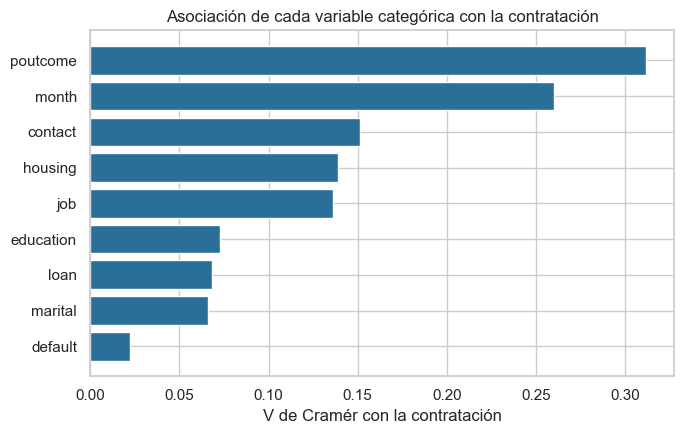

poutcome     0.312
month        0.260
contact      0.151
housing      0.139
job          0.136
education    0.073
loan         0.068
marital      0.066
default      0.022
dtype: float64


In [11]:
from scipy.stats import chi2_contingency

def cramer_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla)[0]
    return float(np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1))))

categoricas = df.select_dtypes(exclude="number").columns.drop("y").tolist()
asociacion = pd.Series({col: cramer_v(df[col], df["contrato"]) for col in categoricas}).sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(asociacion.index, asociacion.values, color="#2a6f97")
plt.xlabel("V de Cramér con la contratación")
plt.title("Asociación de cada variable categórica con la contratación")
plt.tight_layout()
guardar("02_asociacion_categoricas")
plt.show()
print(asociacion.sort_values(ascending=False).round(3))

**Lectura.** La V de Cramér ordena las categóricas por su relación con la contratación. `poutcome` (0,312) y
`month` (0,260) son las más asociadas, seguidas por `contact` (0,151), `housing` (0,139) y `job` (0,136).
`education`, `loan` y `marital` rondan 0,07, y `default` casi no se relaciona (0,022). Es el mismo
orden que luego aparece en las importancias del árbol y de XGBoost, lo que muestra que el análisis
descriptivo ya anticipaba qué variables iban a pesar.

## Por qué descarté `duration`

Medí cuánta información contiene la duración de la llamada, con la diferencia de medianas entre clases y
el ROC-AUC que se obtendría usando **solo** esa variable como puntaje.

In [12]:
from sklearn.metrics import roc_auc_score

mediana_duracion = duracion.groupby(df["y"]).median()
print("Mediana de duration por clase (segundos):")
print(mediana_duracion)
print("\nROC-AUC usando solo duration:", round(roc_auc_score(df["contrato"], duracion), 4))

Mediana de duration por clase (segundos):
y
no     164.0
yes    426.0
Name: duration, dtype: float64

ROC-AUC usando solo duration: 0.8076


**Lectura.** La duración mediana de las llamadas que terminan en contratación es de 426 segundos,
contra 164 de las que no. Usada como único puntaje, `duration` alcanza un ROC-AUC de 0,808, un valor
que ninguno de los cuatro modelos completos, que no la usan, alcanza. Eso confirma que la duración es
consecuencia del interés del cliente y no un dato disponible antes de llamar, y que incluirla haría
que cualquier modelo se viera mucho mejor de lo que realmente sería al usarlo para decidir a quién
llamar. La descarté del experimento.